Oefening 1: Exploratie

In [ ]:
import pandas as pd
import json
import numpy as np

In [ ]:
movies_df_raw = pd.read_csv('../data/movies.csv')
movies_df = movies_df_raw.assign(
                                release_date = pd.col('release_date').astype('datetime64[ns]'),
                                 genres = pd.col('genres').map(lambda s: json.loads(s.replace("'", '"')))
)

Oefening 1.1: Gebruik df.sample(), df.describe() en df.corr(numeric_only = True) om een eerste indruk van de dataset te krijgen. Wat zijn je observaties? Zijn er kolommen met ouliers, of met hele brede staarten (wat kunnen we daar mee doen bij het plotten / verbanden bekijken?)?

Oefening 1.2: Gebruik df.isnull().mean(). Zijn er kolommen die veel nullwaarden bevatten? Zijn er waarden die volgens .isnull niet null zijn, maar die we eigenlijk wel als ontbrekend zouden moeten beschouwen? Hint: Zoek op 'Last Summer in the Hamptons' in de dataset en op Imdb. Kun je een patroon vinden in de verdeling van deze nulls? Wat zijn je conclusies voor de bruikbaarheid van deze set?

Oefening 1.3: Hoeveel films komen er per taal (original language) voor? Hoe worden films aan de IMDb toegevoegd? In hoeverre denk je dat getallen die we obv. de IMDb berekenen representatief zijn?

Bonus: Oefening 1.4: Welke andere aspecten van de dataset lijken je belangrijk om te exploreren voor verder gebruik? Deze kun je zo met de groep delen.

### 2: Visualisatie

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# Focus op Engelstalige en recente films omdat de set daarvoor representatiever is:

movies_in_scope = (movies_df.loc[
                                    (pd.col('release_date') >= '2000-01-01')
                                    & (pd.col('original_language') == 'en')
                                    ]
)

Oefening 2.1: Recreëer deze plot met (enkel) matplotlib.

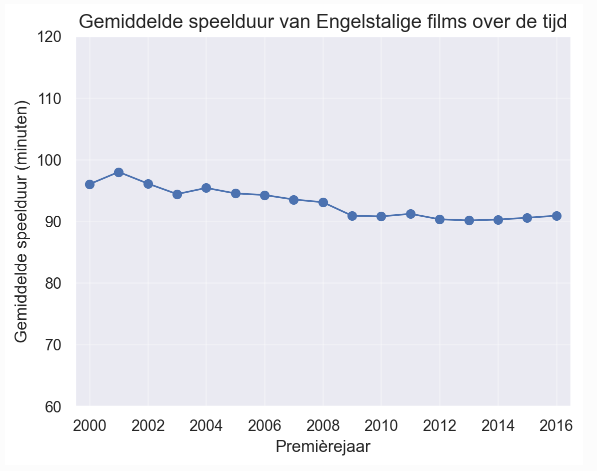

In [ ]:
sns.set_theme(style="darkgrid") 

In [ ]:
yearly_avg = movies_in_scope.loc[
    (pd.col('release_date') <= '2016-12-31') # Vulling van de dataset voor films uit 2017 is niet compleet
].assign(release_year = ...).groupby(..., as_index = False).agg(...) 

fig, ax = plt.subplots()
...
plt.show()

Oefening 2.2:  Recreëer deze plot met sns.violinplot. Heb je interessante observaties?

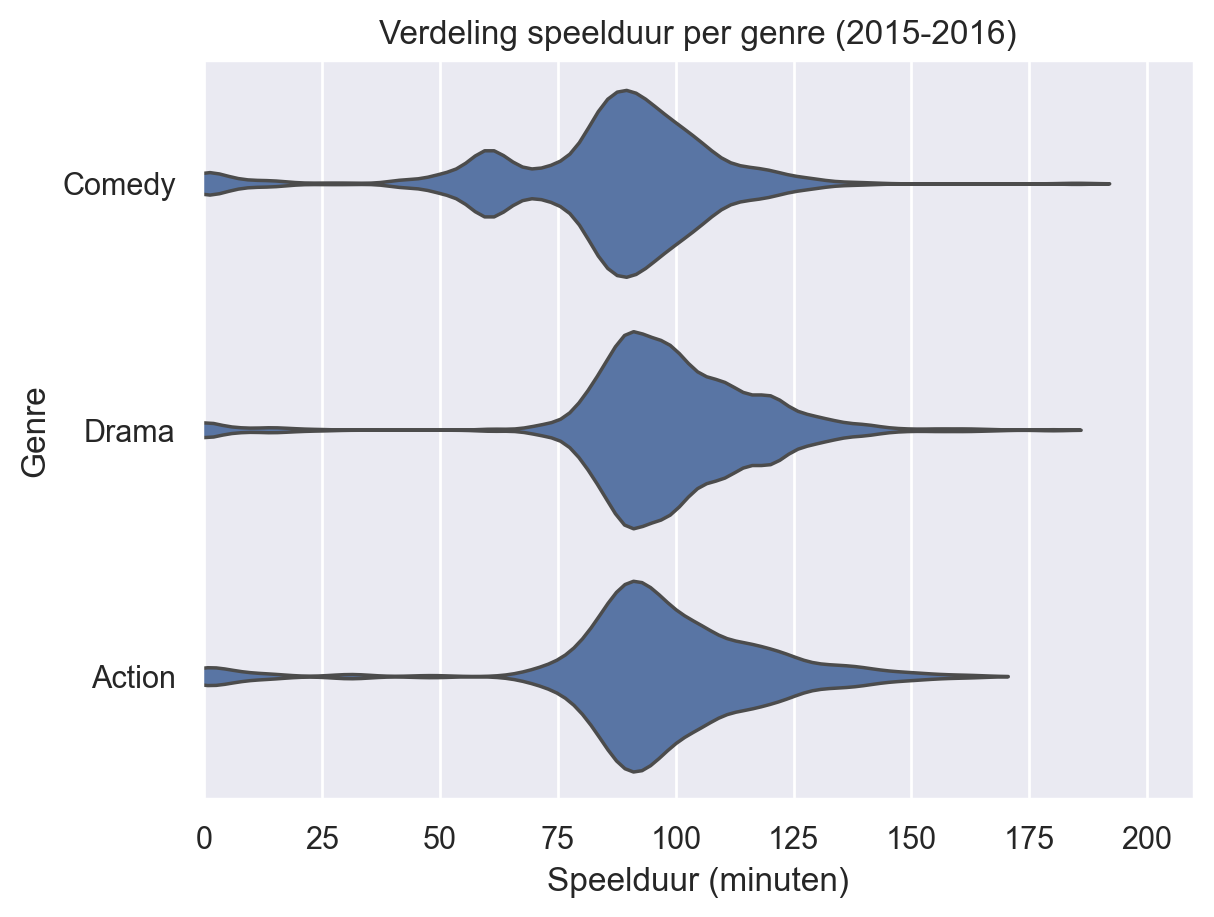

In [ ]:
upper_runtime_limit = 210 # Focus only on movies up to 3 1/2 hours

movies_in_timeframe = movies_in_scope.loc[
    ...
]

movies_with_relevant_genres = movies_in_timeframe.explode("genres").loc[...]

fig, ax = plt.subplots()

sns.violinplot(
    ...,
    ax = ax
    )

...

plt.show()

Oefening 2.3: Recreëer deze plot met sns.jointplot. (Hint: gebruik graph.ax_joint om de axes van de subplots tegelijkertijd aan te spreken). Welke conclusies trek je uit de plot?

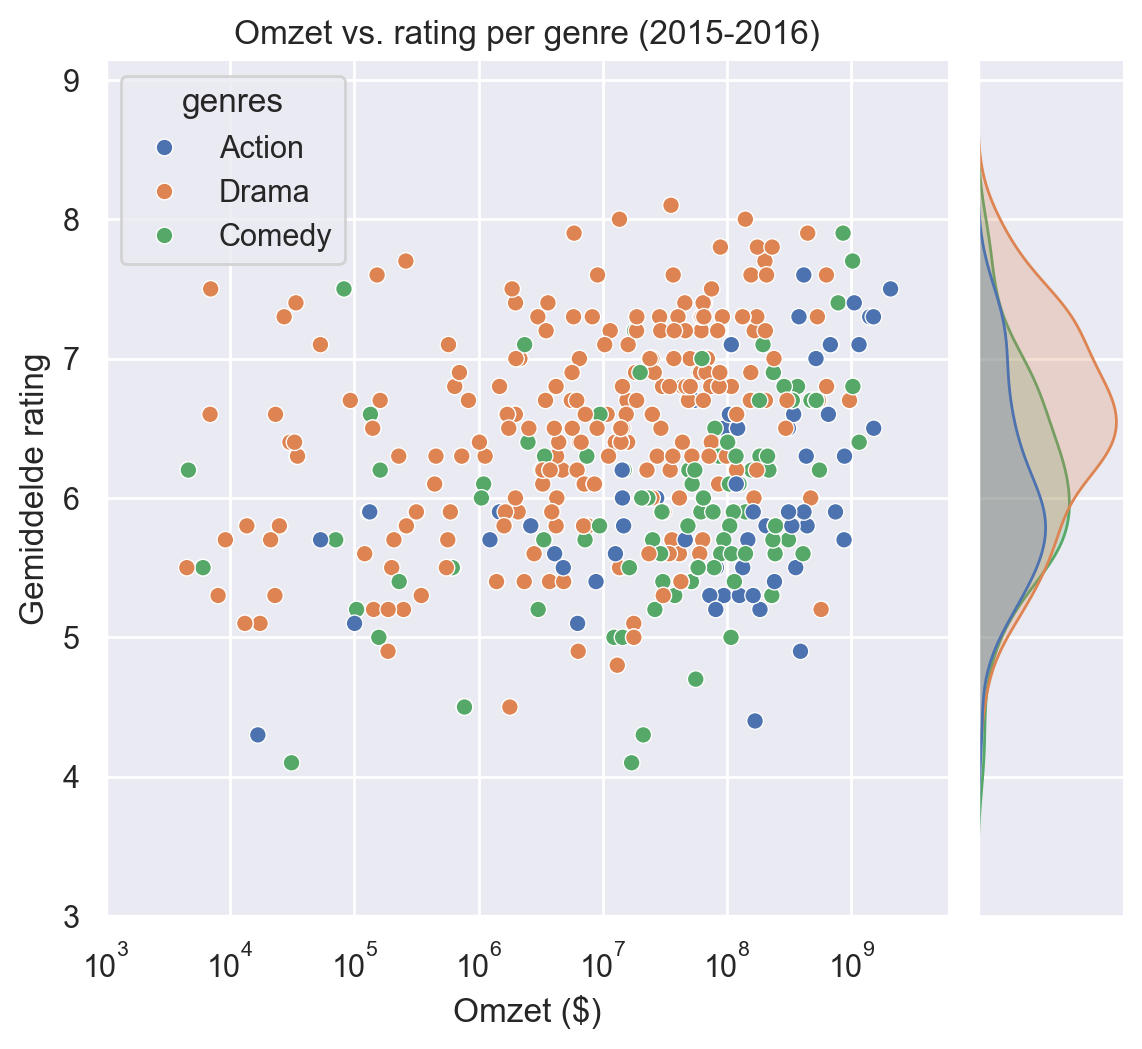

In [ ]:
g = sns.jointplot(movies_with_relevant_genres.dropna(subset = ['revenue']), ...)

g.ax_marg_x.remove() # Verwijdert de histogram over de x-as
g.ax_joint.set_xscale(...)

plt.show()

Bonus: Oefening 2.4: Welk van bovenstaande plots denk je te kunnen verbeteren, visueel en/of qua inzichten we er uit kunnen halen? Pimp deze plot.

Oefening 3.1: Draai deze code, scroll om in te zoomen en houd je muis over de films rechtsboven. Herken je ze? Is de informatie die er bij staat nuttig? Gebruik vervolgens chart.save('filename.svg') om de chart als svg op te slaan. Zoom in. Wat valt je op?

In [ ]:
import altair as alt

In [ ]:
movies_with_relevant_genres =  movies_in_scope.loc[
    (pd.col("release_date") >= "2015-01-02")
    & (pd.col("release_date") <= "2016-12-30")].dropna(subset = ['revenue']).explode('genres').loc[
        pd.col("genres").isin(["Action", "Drama", "Comedy"])
    ]

# Rename columns for altair plot
movies_df_renamed = movies_with_relevant_genres.rename(
        columns = {"vote_average": "Gemiddelde rating", "title": "Titel", "vote_count": "Aantal stemmen", "revenue": "Omzet", "genres": "Genre"}
)

chart = (
        alt.Chart(movies_df_renamed)
            .mark_circle(size=60)
            .encode(
            x=alt.X('Omzet',scale=alt.Scale(type='log', domain=[1_000, 10_000_000_000]),
                    axis=alt.Axis(
                values=[1_000, 100_000, 10_000_000, 1_000_000_000],
                format="$.0e"
            )
                        ),
            y='Gemiddelde rating',
            color='Genre',
            tooltip = ['Titel', 'Omzet', 'Gemiddelde rating', 'Aantal stemmen', 'Genre']
            )
        )

chart = chart.add_params(
     alt.selection_interval(bind='scales')
)

chart

Oefening 3.2, vrije opdracht: Welke hypothesen wil je graag toetsen over deze dataset? Hoe wil je dat visualizeren? Breng deze ideeën in de praktijk met wat je deze cursus geleerd hebt! Kies zelf wat voor visualisatie je wilt maken, en of je dit met matplotlib, seaborn, altair (of great tables, ...) wilt doen.